# Testing Attention Heads on Parity task

The purpose of this notebook is to train simple attention heads on the parity task to understand if the linearity and the relational bottleneck are enough.

## Imports

In [1]:
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from relational_attention.tasks import ParityDataset
from relational_attention.models import SelfAttentionHead, RelationalAttentionHead, AttentionClassifier
from relational_attention.training import train_model

In [2]:
torch.manual_seed(42)

## Initialize models and train on XOR task

### Initialize task

In [3]:
# Parameters
num_samples = 200
num_bits = 2
num_vectors = 1
vector_len = num_bits
head_dim = num_bits

In [4]:
dataset = ParityDataset(num_samples=num_samples, num_bits=num_bits)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

### Initialize models

In [5]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead, linear=True
)

### Train models on parity task

In [6]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [7]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 188.70it/s, loss=0.6799]


In [8]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 211.17it/s, loss=0.0076]


In [9]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 190.19it/s, loss=0.6932]


In [10]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 191.86it/s, loss=0.0111]


### Plot training dynamics

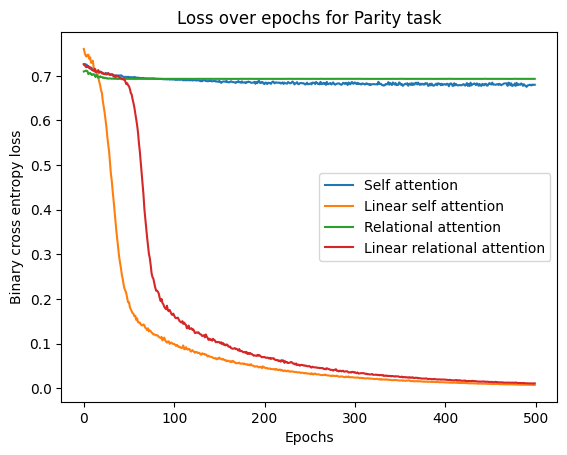

In [11]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for Parity task')
plt.legend()
plt.show()

## Initialize models and train on parity task

In [12]:
# Parameters
num_samples = 200
num_bits = 4
num_vectors = 1
vector_len = num_bits
head_dim = num_bits

In [13]:
dataset = ParityDataset(num_samples=num_samples, num_bits=num_bits)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [14]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=vector_len, head_dim=head_dim, context_size=num_vectors, attn_cls=RelationalAttentionHead, linear=True
)

In [15]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [16]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 189.55it/s, loss=0.6821]


In [17]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 205.79it/s, loss=0.6735]


In [18]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 196.00it/s, loss=0.6932]


In [19]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:02<00:00, 214.27it/s, loss=0.6815]


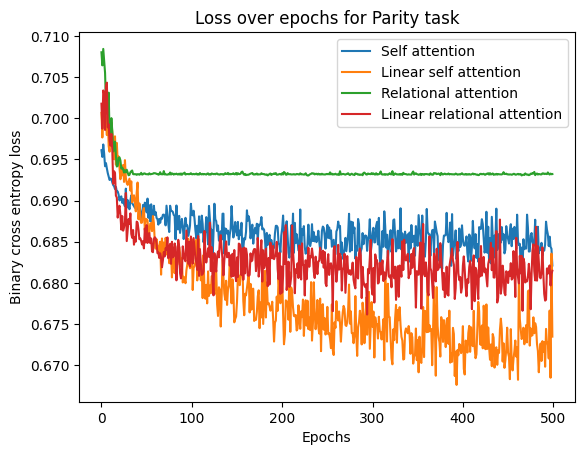

In [20]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for Parity task')
plt.legend()
plt.show()